# Energy Forecasting Notebook

This notebook trains a next-day electricity demand forecast using historical PJM energy usage, calendar features, lag features, rolling averages, and ambient temperature.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv('../data/PJME_hourly.csv', parse_dates=['Datetime'])
df = df.sort_values('Datetime').reset_index(drop=True)
df.head()

,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


In [3]:
df['hour'] = df['Datetime'].dt.hour
df['day'] = df['Datetime'].dt.day
df['month'] = df['Datetime'].dt.month
df['year'] = df['Datetime'].dt.year
df['weekday'] = df['Datetime'].dt.dayofweek
df['weekofyear'] = df['Datetime'].dt.isocalendar().week.astype(int)
df['lag_24'] = df['PJME_MW'].shift(24)
df['lag_168'] = df['PJME_MW'].shift(168)
df['rolling24'] = df['PJME_MW'].shift(1).rolling(24).mean()
df['rolling168'] = df['PJME_MW'].shift(1).rolling(168).mean()
df['target'] = df['PJME_MW'].shift(-24)
df.head()

,Datetime,PJME_MW,hour,day,month,year,weekday,weekofyear,lag_24,lag_168,rolling24,rolling168,target
0,2002-01-01 01:00:00,30393.0,1,1,1,2002,1,1,NaN,NaN,NaN,NaN,28121.0
1,2002-01-01 02:00:00,29265.0,2,1,1,2002,1,1,NaN,NaN,NaN,NaN,27437.0
2,2002-01-01 03:00:00,28357.0,3,1,1,2002,1,1,NaN,NaN,NaN,NaN,27301.0
3,2002-01-01 04:00:00,27899.0,4,1,1,2002,1,1,NaN,NaN,NaN,NaN,27533.0
4,2002-01-01 05:00:00,28057.0,5,1,1,2002,1,1,NaN,NaN,NaN,NaN,28405.0


In [4]:
weather_path = '../data/weather.csv'
try:
    weather = pd.read_csv(weather_path, parse_dates=['Datetime'])
    df = df.merge(weather[['Datetime','temperature']], on='Datetime', how='left')
except FileNotFoundError:
    df['temperature'] = np.sin(np.arange(len(df)) / 24.0) * 10 + 20
    print('weather.csv not found. Using a synthetic temperature column for demonstration.')
df[['Datetime','temperature']].head()

weather.csv not found. Using a synthetic temperature column for demonstration.


,Datetime,temperature
0,2002-01-01 01:00:00,20.000000
1,2002-01-01 02:00:00,20.416546
2,2002-01-01 03:00:00,20.832369
3,2002-01-01 04:00:00,21.246747
4,2002-01-01 05:00:00,21.658961


In [5]:
feature_columns = ['hour','day','month','year','weekday','weekofyear','lag_24','lag_168','rolling24','rolling168','temperature']
model_df = df.dropna(subset=feature_columns + ['target']).copy()
train = model_df.loc[model_df['Datetime'] < '2018-01-01'].copy()
test = model_df.loc[model_df['Datetime'] >= '2018-01-01'].copy()

X_train = train[feature_columns]
y_train = train['target']
X_test = test[feature_columns]
y_test = test['target']

In [6]:
model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [7]:
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
r2 = r2_score(y_test, pred)
print(f'MAE: {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R2: {r2:.4f}')

MAE: 2469.90
RMSE: 3312.54
R2: 0.7205


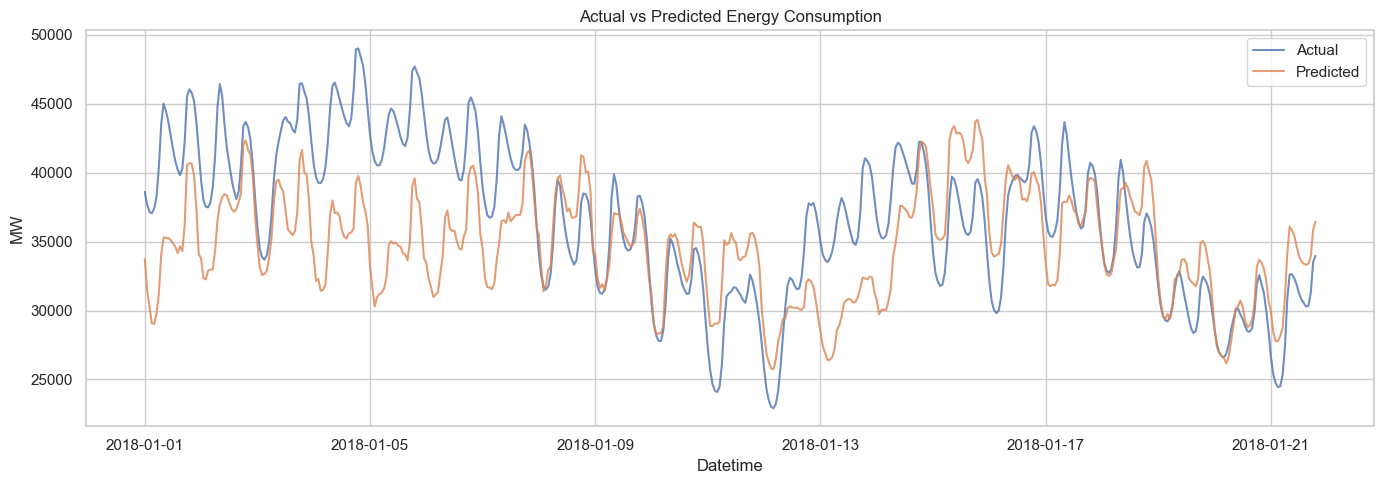

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(test['Datetime'].head(500), y_test.head(500), label='Actual', alpha=0.8)
plt.plot(test['Datetime'].head(500), pred[:500], label='Predicted', alpha=0.8)
plt.legend()
plt.title('Actual vs Predicted Energy Consumption')
plt.xlabel('Datetime')
plt.ylabel('MW')
plt.tight_layout()
plt.show()